# CropVision AI: Honest Tomato Leaf Disease Screening, Built for the Field
**Team Fella AI** · AI Innovation Hackathon 2026 · AI/ML Methodology, Challenge 07

**Question:** a leaf-disease model trained on clean lab photos (PlantVillage) looks excellent in the lab. How does it behave on real field photos (PlantDoc) it has never seen, can its confidence be trusted, and how much field data is needed to close the gap?

**How to run:** Runtime → T4 GPU. First set `SMOKE = True` in section 2 and run all cells (about 5 minutes) to check everything works. Then set `SMOKE = False`, restart the runtime and run all cells (about 30 minutes).

**Notes (edit if inaccurate):**
- This notebook was run in the hackathon development window on 20 Oct 2026, and every number in our submission comes from this run. Parts of the pipeline were tried in a rehearsal beforehand.
- AI assistance (Claude) was used to help draft and debug the code and to plan the analysis. The team ran the experiments, checked the results and wrote the interpretation.
- All data are public: PlantVillage (Hughes and Salathé, 2015) and PlantDoc (Singh et al., 2020, CC BY 4.0).

**Contents:** 1 Setup · 2 Data · 3 Model and training · 4 Headline lab-vs-field result · 5 Calibration and deferral · 6 Robustness · 7 Grad-CAM · 8 Field-data sweep · 9 Save and summary · 10 Demo

## 1. Setup
Install libraries and mount Google Drive so models and results survive a disconnect.

In [14]:
!pip install -q grad-cam gradio
from google.colab import drive, files
drive.mount('/content/drive')
import os, shutil, random, json, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
from torchvision.transforms import functional as TF
from sklearn.metrics import f1_score, confusion_matrix, recall_score
from sklearn.model_selection import StratifiedKFold, train_test_split

OUT = '/content/drive/MyDrive/cropvision_final'; os.makedirs(OUT, exist_ok=True)
FIG = Path('documentation/figures'); FIG.mkdir(parents=True, exist_ok=True)
R = {}                      # results collected here for the README
T0 = time.time()
print('torch', torch.__version__, '| GPU available:', torch.cuda.is_available())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
torch 2.11.0+cu130 | GPU available: True


## 2. Data
- **Training (lab):** PlantVillage colour images of 8 tomato classes. Training images are capped per class and class-balanced by weighted sampling.
- **Lab validation:** a random held-out part of PlantVillage. It likely contains near-duplicate shots of the same leaves, so lab accuracy is flattering. That is part of the point of this project.
- **Testing (field):** all PlantDoc images of the same 8 classes (its train and test folders combined). Never used for training in the main experiments.
- Excluded: spider mites (only 2 PlantDoc images) and target spot (no PlantDoc equivalent).
- The PlantDoc "yellow virus" folder is assumed to be yellow leaf curl virus (we checked a few images: [yes / no, edit]).

In [15]:
!git clone -q --depth 1 https://github.com/pratikkayal/PlantDoc-Dataset
!git clone -q --depth 1 --filter=blob:none --sparse https://github.com/spMohanty/PlantVillage-Dataset
!cd PlantVillage-Dataset && git sparse-checkout set raw/color

fatal: destination path 'PlantDoc-Dataset' already exists and is not an empty directory.
fatal: destination path 'PlantVillage-Dataset' already exists and is not an empty directory.


In [16]:
CLASSES = ['bacterial_spot', 'early_blight', 'healthy', 'late_blight',
           'leaf_mold', 'mosaic_virus', 'septoria_leaf_spot', 'yellow_leaf_curl_virus']
NC = len(CLASSES)
FOLDERS = {   # class: (PlantVillage folder, PlantDoc folder)
 'bacterial_spot': ('Tomato___Bacterial_spot', 'Tomato leaf bacterial spot'),
 'early_blight': ('Tomato___Early_blight', 'Tomato Early blight leaf'),
 'healthy': ('Tomato___healthy', 'Tomato leaf'),
 'late_blight': ('Tomato___Late_blight', 'Tomato leaf late blight'),
 'leaf_mold': ('Tomato___Leaf_Mold', 'Tomato mold leaf'),
 'mosaic_virus': ('Tomato___Tomato_mosaic_virus', 'Tomato leaf mosaic virus'),
 'septoria_leaf_spot': ('Tomato___Septoria_leaf_spot', 'Tomato Septoria leaf spot'),
 'yellow_leaf_curl_virus': ('Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato leaf yellow virus'),
}
PV_ROOT, PD_ROOT = '/content/data/plantvillage_tomato', '/content/data/plantdoc_tomato'
shutil.rmtree('/content/data', ignore_errors=True)
rows = []
for c in CLASSES:
    pv_dir, pd_dir = FOLDERS[c]
    os.makedirs(f'{PV_ROOT}/{c}'); os.makedirs(f'{PD_ROOT}/{c}')
    src = f'PlantVillage-Dataset/raw/color/{pv_dir}'; n_pv = 0
    for f in sorted(os.listdir(src)):
        os.symlink(os.path.abspath(f'{src}/{f}'), f'{PV_ROOT}/{c}/{f}'); n_pv += 1
    n_pd = 0
    for split in ['train', 'test']:
        d = f'PlantDoc-Dataset/{split}/{pd_dir}'
        for f in sorted(os.listdir(d)):
            shutil.copy(f'{d}/{f}', f'{PD_ROOT}/{c}/{split}_{f}'); n_pd += 1
    rows.append(dict(cls=c, plantvillage_available=n_pv, plantdoc_field=n_pd))
counts_tbl = pd.DataFrame(rows); print(counts_tbl.to_string(index=False))
counts_tbl.to_csv('documentation/dataset_counts.csv', index=False)
print('total field images:', counts_tbl.plantdoc_field.sum(), '(expected 744)')

                   cls  plantvillage_available  plantdoc_field
        bacterial_spot                    2127             110
          early_blight                    1000              88
               healthy                    1591              63
           late_blight                    1909             111
             leaf_mold                     952              91
          mosaic_virus                     373              54
    septoria_leaf_spot                    1771             151
yellow_leaf_curl_virus                    5357              76
total field images: 744 (expected 744)


In [17]:
SMOKE = False         # True = tiny test run (24 images per class, 1+1 epochs). Set False for the real run.
SEED = 42; IMG = 224; BATCH = 64
TRAIN_CAP = 600       # max training images per class
VAL_CAP = 150         # max lab-validation images per class
EPOCHS_HEAD, EPOCHS_FT = (1, 1) if SMOKE else (3, 4)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'

def list_images(root):
    items = []
    for ci, c in enumerate(CLASSES):
        d = f'{root}/{c}'
        for f in sorted(os.listdir(d)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png')): items.append((f'{d}/{f}', ci))
    return items

def per_class_cap(items, k, seed=SEED):
    r = random.Random(seed); out = []
    for ci in range(NC):
        xs = [x for x in items if x[1] == ci]; r.shuffle(xs); out += xs[:k]
    return out

rng = random.Random(SEED); pv = list_images(PV_ROOT); train, val = [], []
for ci in range(NC):
    xs = [x for x in pv if x[1] == ci]; rng.shuffle(xs)
    n_val = min(VAL_CAP, int(0.2 * len(xs))); n_tr = min(TRAIN_CAP, len(xs) - n_val)
    val += xs[:n_val]; train += xs[n_val:n_val + n_tr]
field = list_images(PD_ROOT)          # PlantDoc: test only
if SMOKE: train, val, field = per_class_cap(train, 24), per_class_cap(val, 24), per_class_cap(field, 24)
y_field = np.array([y for _, y in field]); y_val = np.array([y for _, y in val])
print('train', len(train), '| lab-val', len(val), '| field', len(field))
print(pd.DataFrame({'train': np.bincount([y for _, y in train], minlength=NC),
                    'lab_val': np.bincount(y_val, minlength=NC),
                    'field': np.bincount(y_field, minlength=NC)}, index=CLASSES))

norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG, scale=(0.4, 1.0)), transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(), transforms.RandomRotation(30), transforms.ColorJitter(0.4, 0.4, 0.4, 0.05),
    transforms.RandomApply([transforms.GaussianBlur(5, (0.1, 2.0))], p=0.3), transforms.ToTensor(), norm])
eval_tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(), norm])

class DS(Dataset):
    def __init__(self, items, tf): self.items, self.tf = items, tf
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        p, y = self.items[i]; return self.tf(Image.open(p).convert('RGB')), y

val_dl = DataLoader(DS(val, eval_tf), batch_size=BATCH, shuffle=False, num_workers=2, pin_memory=True)

train 4499 | lab-val 1124 | field 744
                        train  lab_val  field
bacterial_spot            600      150    110
early_blight              600      150     88
healthy                   600      150     63
late_blight               600      150    111
leaf_mold                 600      150     91
mosaic_virus              299       74     54
septoria_leaf_spot        600      150    151
yellow_leaf_curl_virus    600      150     76


## 3. Model and training
EfficientNet-B0 pretrained on ImageNet. The classifier head is trained first, then the whole network is fine-tuned. The checkpoint is chosen on **lab** validation loss only, never on field data. Training is class-balanced with augmentation for crop, rotation, lighting and blur. The same training function is reused for the field-data sweep in section 8.

In [18]:
def build_model():
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, NC)
    return m.to(dev)

def make_train_dl(items):
    cnt = np.bincount([y for _, y in items], minlength=NC)
    w = [1.0 / cnt[y] for _, y in items]
    sampler = WeightedRandomSampler(w, num_samples=len(items), replacement=True)
    return DataLoader(DS(items, train_tf), batch_size=BATCH, sampler=sampler, num_workers=2, pin_memory=True)

def train_model(train_items, ckpt, verbose=True):
    m = build_model(); tdl = make_train_dl(train_items)
    scaler = torch.amp.GradScaler('cuda', enabled=(dev == 'cuda')); best = {'loss': 1e9}
    def run_epoch(loader, opt=None):
        training = opt is not None; m.train(training); tot_loss = tot_ok = n = 0
        for x, y in loader:
            x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)
            with torch.set_grad_enabled(training):
                with torch.autocast(device_type=dev, dtype=torch.float16, enabled=(dev == 'cuda')):
                    out = m(x); loss = F.cross_entropy(out.float(), y)
            if training:
                opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot_loss += loss.item() * len(y); tot_ok += (out.argmax(1) == y).sum().item(); n += len(y)
        return tot_loss / n, tot_ok / n
    def fit(epochs, lr, params, tag):
        for p in m.parameters(): p.requires_grad = False
        for p in params: p.requires_grad = True
        opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        for e in range(epochs):
            tl, ta = run_epoch(tdl, opt); vl, va = run_epoch(val_dl); sched.step()
            if verbose: print(f'[{tag}] epoch {e+1}/{epochs} train loss {tl:.3f} acc {ta:.3f} | lab-val loss {vl:.3f} acc {va:.3f}')
            if vl < best['loss']: best['loss'] = vl; torch.save(m.state_dict(), ckpt)
    fit(EPOCHS_HEAD, 1e-3, m.classifier.parameters(), 'head')
    fit(EPOCHS_FT, 1e-4, m.parameters(), 'finetune')
    m.load_state_dict(torch.load(ckpt, map_location=dev)); m.eval()
    return m, best['loss']

model, best_val_loss = train_model(train, f'{OUT}/best.pt')
print('loaded best checkpoint, lab-val loss', round(best_val_loss, 4), '| elapsed (min):', round((time.time()-T0)/60, 1))

[head] epoch 1/3 train loss 1.405 acc 0.603 | lab-val loss 0.860 acc 0.788
[head] epoch 2/3 train loss 0.925 acc 0.739 | lab-val loss 0.665 acc 0.825
[head] epoch 3/3 train loss 0.816 acc 0.767 | lab-val loss 0.619 acc 0.830
[finetune] epoch 1/4 train loss 0.490 acc 0.850 | lab-val loss 0.241 acc 0.925
[finetune] epoch 2/4 train loss 0.223 acc 0.932 | lab-val loss 0.151 acc 0.952
[finetune] epoch 3/4 train loss 0.174 acc 0.946 | lab-val loss 0.122 acc 0.964
[finetune] epoch 4/4 train loss 0.141 acc 0.957 | lab-val loss 0.113 acc 0.967
loaded best checkpoint, lab-val loss 0.1134 | elapsed (min): 5.2


In [19]:
@torch.no_grad()
def get_logits(m, items, tf=eval_tf):
    dl = DataLoader(DS(items, tf), batch_size=BATCH, shuffle=False, num_workers=2)
    m.eval(); outs = []
    for x, _ in dl:
        with torch.autocast(device_type=dev, dtype=torch.float16, enabled=(dev == 'cuda')):
            outs.append(m(x.to(dev)).float().cpu())
    return torch.cat(outs).numpy()

val_logits, field_logits = get_logits(model, val), get_logits(model, field)
np.savez(f'{OUT}/logits.npz', val_logits=val_logits, y_val=y_val, field_logits=field_logits, y_field=y_field,
         field_paths=np.array([p for p, _ in field]))
print('saved logits (so the analysis below can be re-run without retraining):', val_logits.shape, field_logits.shape)

saved logits (so the analysis below can be re-run without retraining): (1124, 8) (744, 8)


## 4. Headline result: lab versus field
Accuracy and macro-F1 on lab validation images and on unseen field images, with bootstrap 95% confidence intervals, plus per-class recall (PlantDoc classes are small, so intervals matter).

**Observation:** On unseen PlantDoc field images the model scores 27.8% accuracy (95% CI 24.5% to 30.9%) and macro-F1 0.230, against 96.7% and 0.966 on the PlantVillage validation split, a gap of 68.9 points. Field accuracy is above the 12.5% chance level but far from usable. Recall varies widely: 77.3% for early blight and 55.9% for late blight, but 3.6% for bacterial spot and 1.9% for mosaic virus. Many classes are predicted as early blight. The lab score is flattering because the validation split comes from the same lab dataset and likely contains near-duplicate images.



LAB   (PlantVillage val): accuracy 0.967 | macro-F1 0.966
FIELD (PlantDoc, unseen): accuracy 0.278 [0.245, 0.309] | macro-F1 0.230 [0.198, 0.260]
Lab-to-field accuracy gap: 68.9 percentage points | chance with 8 classes = 12.5%
predicted counts on field: {'bacterial_spot': 12, 'early_blight': 399, 'healthy': 35, 'late_blight': 173, 'leaf_mold': 17, 'mosaic_virus': 2, 'septoria_leaf_spot': 79, 'yellow_leaf_curl_virus': 27}
                 class  n_field  recall  ci_low  ci_high
        bacterial_spot      110   0.036   0.009    0.073
          early_blight       88   0.773   0.682    0.852
               healthy       63   0.190   0.095    0.286
           late_blight      111   0.559   0.468    0.649
             leaf_mold       91   0.099   0.044    0.165
          mosaic_virus       54   0.019   0.000    0.056
    septoria_leaf_spot      151   0.232   0.172    0.298
yellow_leaf_curl_virus       76   0.211   0.118    0.303


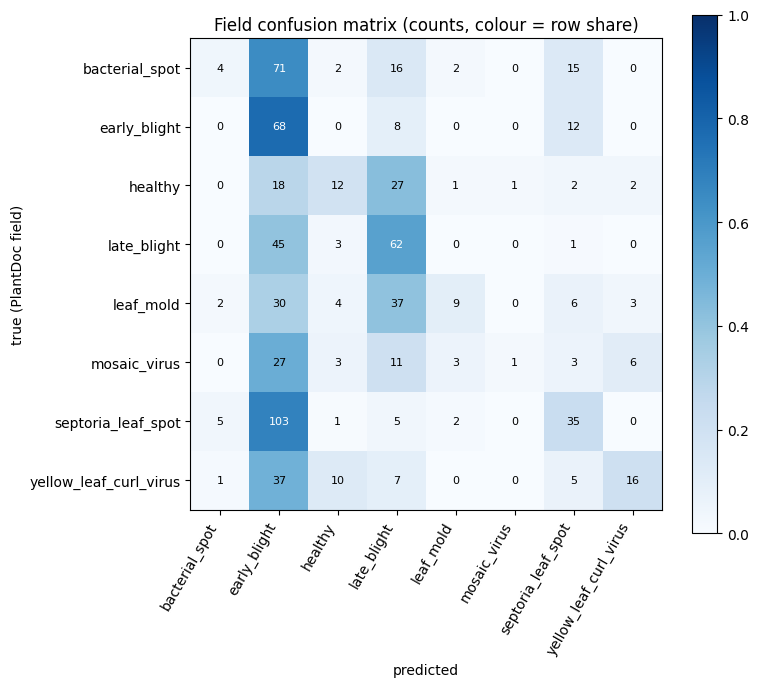

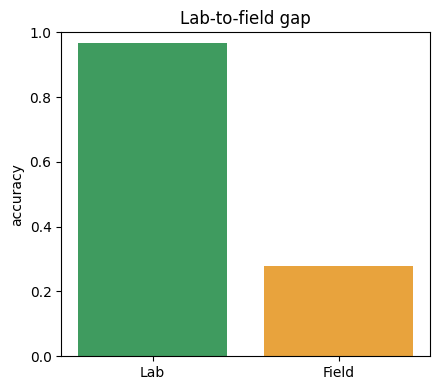

In [20]:
def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
def macro_f1(y, p): return f1_score(y, p, average='macro', labels=list(range(NC)), zero_division=0)
def boot_ci(y, p, fn, B=1000):
    r = np.random.default_rng(SEED); n = len(y); v = []
    for _ in range(B):
        i = r.integers(0, n, n); v.append(fn(y[i], p[i]))
    return np.percentile(v, [2.5, 97.5])

pred_val, pred_field = val_logits.argmax(1), field_logits.argmax(1)
lab_acc, field_acc = (pred_val == y_val).mean(), (pred_field == y_field).mean()
lab_f1, field_f1 = macro_f1(y_val, pred_val), macro_f1(y_field, pred_field)
f1_lo, f1_hi = boot_ci(y_field, pred_field, macro_f1)
acc_lo, acc_hi = boot_ci(y_field, pred_field, lambda a, b: (a == b).mean())
print(f'LAB   (PlantVillage val): accuracy {lab_acc:.3f} | macro-F1 {lab_f1:.3f}')
print(f'FIELD (PlantDoc, unseen): accuracy {field_acc:.3f} [{acc_lo:.3f}, {acc_hi:.3f}] | macro-F1 {field_f1:.3f} [{f1_lo:.3f}, {f1_hi:.3f}]')
print(f'Lab-to-field accuracy gap: {100*(lab_acc-field_acc):.1f} percentage points | chance with 8 classes = 12.5%')
print('predicted counts on field:', {CLASSES[i]: int((pred_field == i).sum()) for i in range(NC)})

rec = recall_score(y_field, pred_field, labels=list(range(NC)), average=None, zero_division=0)
r = np.random.default_rng(SEED); rows = []
for c in range(NC):
    ok = (pred_field[y_field == c] == c).astype(float)
    bs = [ok[r.integers(0, len(ok), len(ok))].mean() for _ in range(1000)]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    rows.append({'class': CLASSES[c], 'n_field': len(ok), 'recall': round(rec[c], 3), 'ci_low': round(lo, 3), 'ci_high': round(hi, 3)})
per_class = pd.DataFrame(rows); print(per_class.to_string(index=False))
per_class.to_csv('documentation/per_class_recall.csv', index=False)

cm = confusion_matrix(y_field, pred_field, labels=list(range(NC))); cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(8, 7)); im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(NC)); ax.set_xticklabels(CLASSES, rotation=60, ha='right'); ax.set_yticks(range(NC)); ax.set_yticklabels(CLASSES)
for i in range(NC):
    for j in range(NC): ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cmn[i, j] > 0.5 else 'black', fontsize=8)
ax.set_xlabel('predicted'); ax.set_ylabel('true (PlantDoc field)'); ax.set_title('Field confusion matrix (counts, colour = row share)')
plt.colorbar(im); plt.tight_layout(); plt.savefig(FIG/'field_confusion_matrix.png', dpi=150); plt.show()

plt.figure(figsize=(4.5, 4)); plt.bar(['Lab', 'Field'], [lab_acc, field_acc], color=['#3f9b5f', '#e8a33d']); plt.ylim(0, 1)
plt.ylabel('accuracy'); plt.title('Lab-to-field gap'); plt.tight_layout(); plt.savefig(FIG/'lab_vs_field_gap.png', dpi=150); plt.show()
R['headline'] = dict(lab_acc=float(lab_acc), field_acc=float(field_acc), field_acc_ci=[float(acc_lo), float(acc_hi)],
    lab_macro_f1=float(lab_f1), field_macro_f1=float(field_f1), field_macro_f1_ci=[float(f1_lo), float(f1_hi)],
    gap_pp=float(100*(lab_acc-field_acc)), n_field=int(len(field)), smoke=SMOKE)
R['per_class_recall'] = per_class.to_dict('records')

## 5. Can we trust the confidence? Calibration and deferral
- **Lab temperature:** fitted on lab validation data only, then applied to field images (we expect overconfidence to remain).
- **Cross-fitted field temperature:** 5 folds on PlantDoc. Each image is scored with a temperature and a deferral threshold that never saw it. This uses labelled field images for calibration only, not for training, so report it separately from the zero-shot headline.
- **Deferral:** for a target accuracy on answered images, how much of the field data can the system answer?

**Observation:** Mean confidence is 68.6% but accuracy is 27.8%, so the model is strongly overconfident on field images (ECE 0.408). Lab temperature scaling (T = 0.80) does not fix this and makes it slightly worse (0.466). Ranking by confidence helps modestly: accuracy on answered images rises to 34.8% at 60% coverage, 39.7% at 40% and 45.3% at 20%, still below 50%. Cross-fitted deferral, which uses labelled field images and so is not zero-shot, reached about 70% accuracy only on about 6% of images and missed its 80% and 90% targets. The flag is a prototype feature, not a safety guarantee.

Mean confidence 0.686 vs accuracy 0.278
Lab temperature T = 0.80 | ECE on field: uncalibrated 0.408, lab-calibrated 0.466
raw confidence, coverage -> accuracy: {'100%': 0.278, '80%': 0.301, '60%': 0.348, '40%': 0.397, '20%': 0.453}
ECE on field, cross-fitted temperature: 0.076

Target acc | coverage | accuracy on answered | accuracy if all answered
   0.70    |  0.063   |   0.702   | 0.278
   0.80    |  0.028   |   0.714   | 0.278
   0.90    |  0.009   |   0.571   | 0.278


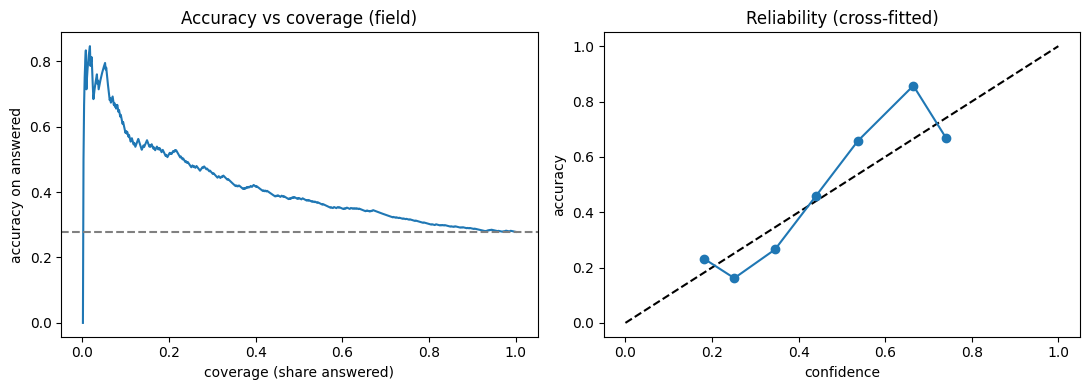

In [21]:
def ece(probs, y, bins=15):
    conf, ok = probs.max(1), (probs.argmax(1) == y); edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return float(e)
#def fit_temp(logits, y):
    #z, t = torch.tensor(logits), torch.tensor(y)
    #logT = torch.zeros(1, requires_grad=True); opt = torch.optim.LBFGS([logT], lr=0.1, max_iter=100)
    #def closure():
        #opt.zero_grad(); l = F.cross_entropy(z / logT.exp(), t); l.backward(); return l
    #opt.step(closure); return float(logT.exp())

def fit_temp(logits, y):
    z, t = torch.tensor(logits, dtype=torch.float32), torch.tensor(y)
    grid = np.exp(np.linspace(np.log(0.05), np.log(20), 400))
    nll = [F.cross_entropy(z / g, t).item() for g in grid]
    return float(grid[int(np.argmin(nll))])

p_raw = softmax(field_logits); conf_raw = p_raw.max(1); ok_raw = (p_raw.argmax(1) == y_field)
T_lab = fit_temp(val_logits, y_val)
cal = dict(mean_confidence=float(conf_raw.mean()), accuracy=float(ok_raw.mean()), T_lab=T_lab,
           ece_uncalibrated=ece(p_raw, y_field), ece_lab_calibrated=ece(softmax(field_logits / T_lab), y_field))
print(f"Mean confidence {cal['mean_confidence']:.3f} vs accuracy {cal['accuracy']:.3f}")
print(f"Lab temperature T = {T_lab:.2f} | ECE on field: uncalibrated {cal['ece_uncalibrated']:.3f}, lab-calibrated {cal['ece_lab_calibrated']:.3f}")

# raw-confidence coverage table (no calibration)
order = np.argsort(-conf_raw); acc_at = np.cumsum(ok_raw[order]) / np.arange(1, len(conf_raw) + 1)
cal['coverage_raw'] = {f'{int(c*100)}%': float(acc_at[max(int(c*len(conf_raw)) - 1, 0)]) for c in [1.0, 0.8, 0.6, 0.4, 0.2]}
print('raw confidence, coverage -> accuracy:', {k: round(v, 3) for k, v in cal['coverage_raw'].items()})

# cross-fitted temperature + deferral threshold on PlantDoc
def pick_threshold(conf, correct, target):
    o = np.argsort(-conf); c = correct[o]; cum = np.cumsum(c) / np.arange(1, len(c) + 1)
    ok = np.where(cum >= target)[0]
    return conf[o][ok.max()] if len(ok) else 1.01          # unreachable target -> accept nothing
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
oof = np.zeros_like(field_logits); targets = [0.7, 0.8, 0.9]; accept = {t: np.zeros(len(y_field), bool) for t in targets}
for k, (tr, te) in enumerate(skf.split(field_logits, y_field)):
    T = fit_temp(field_logits[tr], y_field[tr]); oof[te] = softmax(field_logits[te] / T)
    ptr = softmax(field_logits[tr] / T); ctr = ptr.max(1); oktr = (ptr.argmax(1) == y_field[tr])
    for t in targets: accept[t][te] = oof[te].max(1) >= pick_threshold(ctr, oktr, t)
cal['ece_cross_fitted'] = ece(oof, y_field); ok_all = (oof.argmax(1) == y_field)
print(f"ECE on field, cross-fitted temperature: {cal['ece_cross_fitted']:.3f}")
cal['deferral'] = []
print('\nTarget acc | coverage | accuracy on answered | accuracy if all answered')
for t in targets:
    a = accept[t]; acc_a = float(ok_all[a].mean()) if a.any() else float('nan')
    cal['deferral'].append(dict(target=t, coverage=float(a.mean()), accuracy_answered=acc_a))
    print(f'   {t:.2f}    |  {a.mean():.3f}   |   {acc_a:.3f}   | {ok_all.mean():.3f}')

conf = oof.max(1); o = np.argsort(-conf); cov = np.arange(1, len(y_field) + 1) / len(y_field); curve = np.cumsum(ok_all[o]) / np.arange(1, len(y_field) + 1)
fig, axs = plt.subplots(1, 2, figsize=(11, 4)); axs[0].plot(cov, curve); axs[0].axhline(ok_all.mean(), ls='--', c='grey')
axs[0].set_xlabel('coverage (share answered)'); axs[0].set_ylabel('accuracy on answered'); axs[0].set_title('Accuracy vs coverage (field)')
edges = np.linspace(0, 1, 11); xs, ys = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (conf > lo) & (conf <= hi)
    if m.sum() >= 3: xs.append(conf[m].mean()); ys.append(ok_all[m].mean())
axs[1].plot([0, 1], [0, 1], 'k--'); axs[1].plot(xs, ys, 'o-'); axs[1].set_xlabel('confidence'); axs[1].set_ylabel('accuracy'); axs[1].set_title('Reliability (cross-fitted)')
plt.tight_layout(); plt.savefig(FIG/'coverage_reliability.png', dpi=150); plt.show()
R['calibration'] = cal

## 6. Robustness to simple image changes
Field accuracy and macro-F1 under darker or brighter images and blur.

In [22]:
conds = {'original': lambda im: im,
         'dark (x0.5)': lambda im: TF.adjust_brightness(im, 0.5),
         'bright (x1.6)': lambda im: TF.adjust_brightness(im, 1.6),
         'blur (sigma 4)': lambda im: TF.gaussian_blur(im, kernel_size=15, sigma=4.0)}
rows = []
for name, fn in conds.items():
    lg = get_logits(model, field, transforms.Compose([transforms.Lambda(fn), eval_tf])); p = lg.argmax(1)
    rows.append({'condition': name, 'accuracy': round(float((p == y_field).mean()), 3), 'macro_F1': round(float(macro_f1(y_field, p)), 3)})
rob = pd.DataFrame(rows); print(rob.to_string(index=False)); rob.to_csv('documentation/robustness.csv', index=False)
R['robustness'] = rows

     condition  accuracy  macro_F1
      original     0.278     0.230
   dark (x0.5)     0.249     0.197
 bright (x1.6)     0.273     0.215
blur (sigma 4)     0.250     0.197


## 7. Grad-CAM
Heatmaps from the last convolutional block (coarse, qualitative). First a random sample of field images, then field images the model got wrong with confidence above 0.9.

**Observation:** In the random sample of field images the heat sometimes falls on the diseased leaf area (for example a correctly predicted late blight leaf), but it often falls on background, stems or other non-leaf regions. Several images are not typical leaf photos (drawings, pressed plants), and one carries a stock-photo watermark. In the confident mistakes we inspected, the heat often sits on spotted leaf tissue, so the model attends to lesions but confuses similar spot diseases (for example bacterial spot predicted as Septoria or early blight). Grad-CAM is coarse and shows where the model looked, not proof of why it decided.

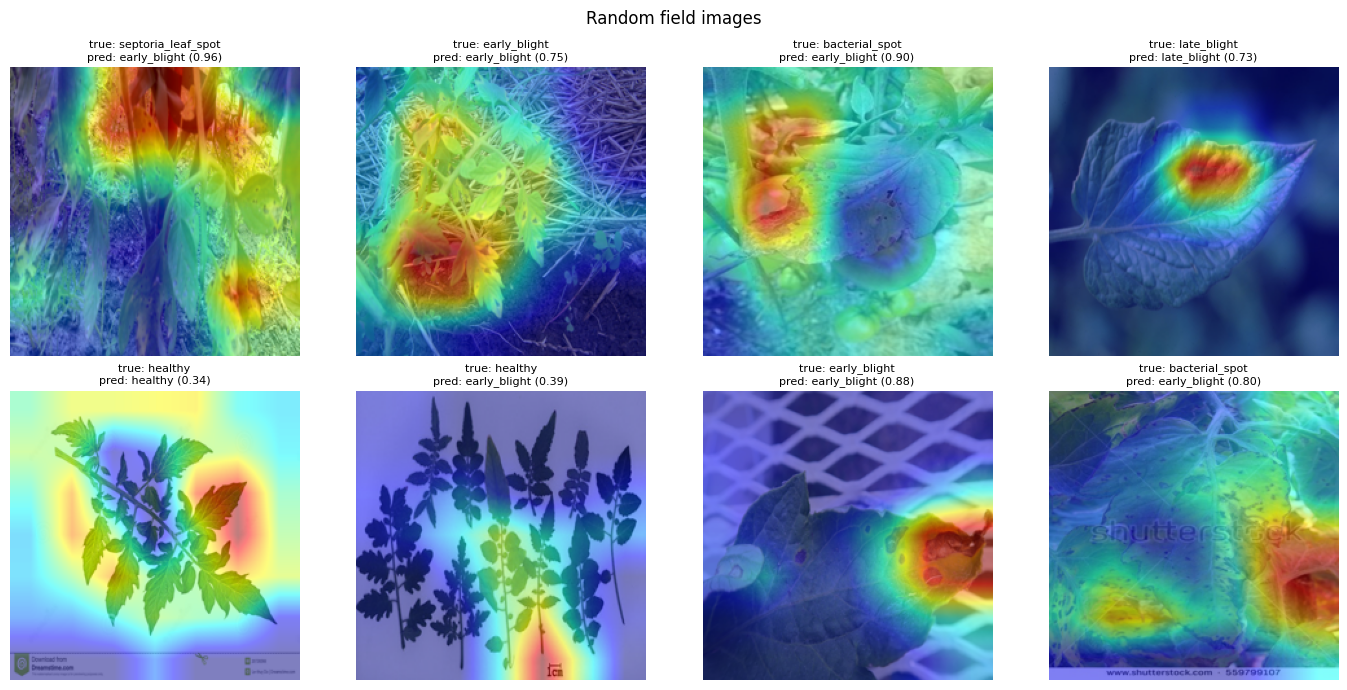

confident mistakes (>0.9): 80 of 537 mistakes


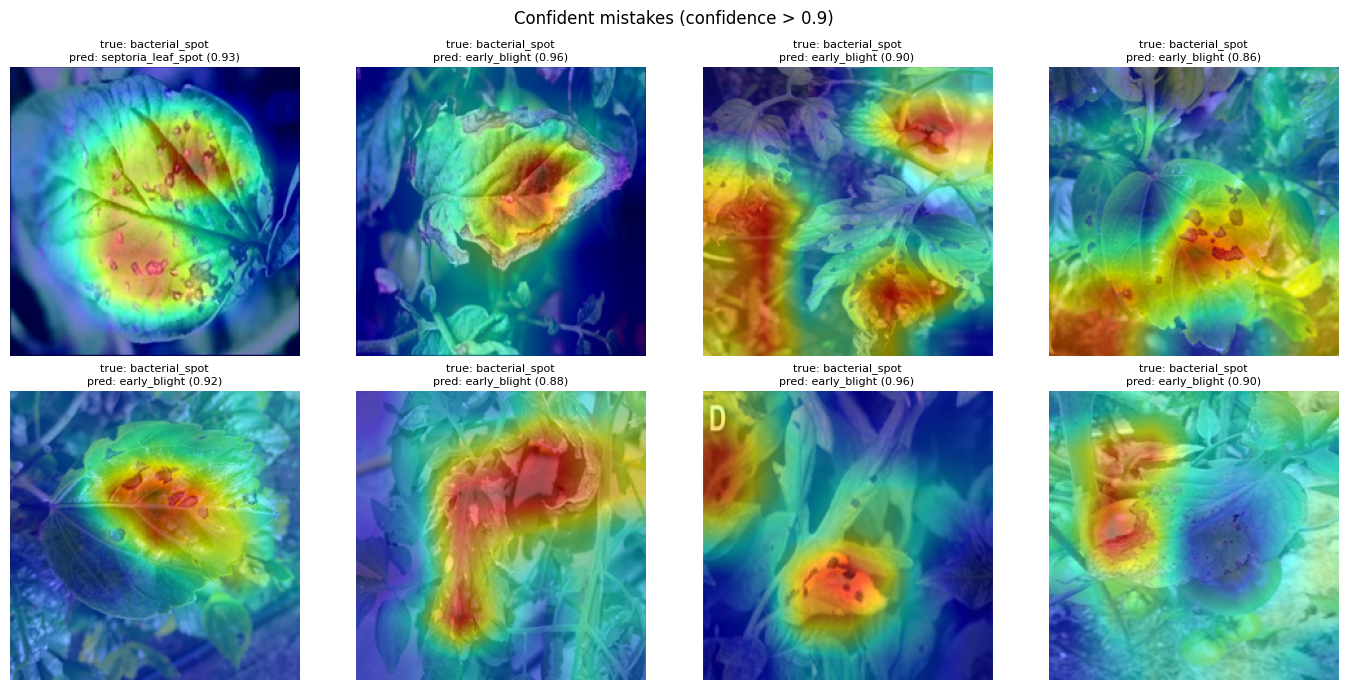

In [23]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
model.eval(); cam = GradCAM(model=model, target_layers=[model.features[-1]])
mean, std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])

def explain(path):
    arr = np.asarray(Image.open(path).convert('RGB').resize((IMG, IMG))) / 255.0
    x = torch.tensor(((arr - mean) / std).transpose(2, 0, 1), dtype=torch.float32).unsqueeze(0).to(dev)
    with torch.no_grad(): probs = F.softmax(model(x).float(), 1)[0].cpu().numpy()
    c = int(probs.argmax()); heat = cam(input_tensor=x, targets=[ClassifierOutputTarget(c)])[0]
    return show_cam_on_image(arr.astype(np.float32), heat, use_rgb=True), CLASSES[c], float(probs[c])

def grid(indices, fname, title):
    fig, axs = plt.subplots(2, 4, figsize=(14, 7)); fig.suptitle(title)
    for ax, i in zip(axs.ravel(), indices):
        vis, name, p = explain(field[i][0]); ax.imshow(vis); ax.axis('off')
        ax.set_title(f'true: {CLASSES[field[i][1]]}\npred: {name} ({p:.2f})', fontsize=8)
    plt.tight_layout(); plt.savefig(FIG/fname, dpi=150); plt.show()

grid(random.Random(SEED).sample(range(len(field)), min(8, len(field))), 'gradcam_random.png', 'Random field images')
bad = np.where((p_raw.argmax(1) != y_field) & (conf_raw > 0.9))[0]
R['confident_mistakes'] = dict(count=int(len(bad)), total_mistakes=int((~ok_raw).sum()))
print('confident mistakes (>0.9):', len(bad), 'of', int((~ok_raw).sum()), 'mistakes')
if len(bad): grid(bad[:8], 'gradcam_confident_mistakes.png', 'Confident mistakes (confidence > 0.9)')

## 8. How much field data closes the gap? (stretch goal)
We hold out half of the field images as a fixed test set, add 0%, 10%, 25% or 50% of all field images to the training data, retrain with the same recipe, and test on the held-out half. This is a separate experiment from the zero-shot result above, and its test set is smaller.

**Caveat:** PlantDoc crops from the same source photo could appear in both parts, which would flatter the numbers.

**Observation:** Adding 10% of the field images (74 images) raised accuracy on the held-out field half from 28.2% to 39.8% (macro-F1 0.242 to 0.380). At 25% it was 40.9% and at 50% 43.3%, so gains slow down and the model remains far below its lab score. This is a single run on 372 test images, and crops from the same source photo may appear in both parts, which could flatter the numbers.

0% field data added: {'acc': 0.28225806451612906, 'macro_f1': 0.24181969253327434, 'n_field_added': 0, 'n_test': 372}
10% field data added: {'acc': 0.3978494623655914, 'macro_f1': 0.3795636437159903, 'n_field_added': 74, 'n_test': 372}
25% field data added: {'acc': 0.40860215053763443, 'macro_f1': 0.40181104420230623, 'n_field_added': 186, 'n_test': 372}
50% field data added: {'acc': 0.4327956989247312, 'macro_f1': 0.43077787271880263, 'n_field_added': 372, 'n_test': 372}


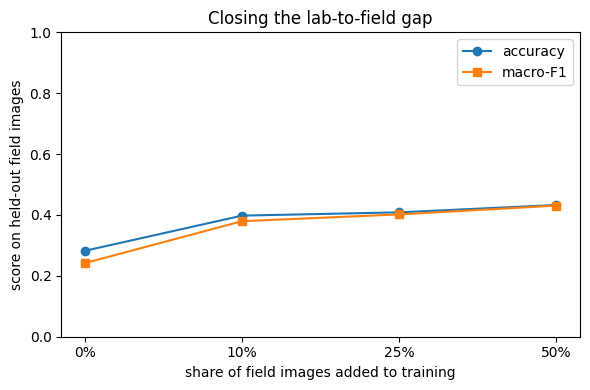

In [24]:
idx = np.arange(len(field))
pool_idx, hold_idx = train_test_split(idx, test_size=0.5, stratify=y_field, random_state=SEED)
hold = [field[i] for i in hold_idx]; y_hold = y_field[hold_idx]
R['sweep'] = {}
for pct, frac in [(0, 0.0), (10, 0.2), (25, 0.5), (50, 1.0)]:      # share of the pool = 0/10/25/50 percent of all field images
    if frac == 0: extra = []
    elif frac == 1.0: extra = [field[i] for i in pool_idx]
    else:
        sub_idx, _ = train_test_split(pool_idx, train_size=frac, stratify=y_field[pool_idx], random_state=SEED)
        extra = [field[i] for i in sub_idx]
    m, _ = train_model(train + extra, f'/content/sweep_{pct}.pt', verbose=False)
    p = get_logits(m, hold).argmax(1)
    R['sweep'][f'{pct}%'] = dict(acc=float((p == y_hold).mean()), macro_f1=float(macro_f1(y_hold, p)), n_field_added=len(extra), n_test=len(hold))
    print(f'{pct}% field data added:', R['sweep'][f'{pct}%'])
    del m; torch.cuda.empty_cache()
ks = list(R['sweep']); plt.figure(figsize=(6, 4))
plt.plot(ks, [R['sweep'][k]['acc'] for k in ks], marker='o', label='accuracy'); plt.plot(ks, [R['sweep'][k]['macro_f1'] for k in ks], marker='s', label='macro-F1')
plt.xlabel('share of field images added to training'); plt.ylabel('score on held-out field images'); plt.ylim(0, 1); plt.legend()
plt.title('Closing the lab-to-field gap'); plt.tight_layout(); plt.savefig(FIG/'field_data_sweep.png', dpi=150); plt.show()

## 9. Save models, figures and results
Everything is saved to Google Drive. The printout below can be pasted into the README results section.

In [28]:
os.makedirs('models', exist_ok=True)
shutil.copy(f'{OUT}/best.pt', 'models/efficientnet_b0_cropvision.pt')
json.dump(R, open('documentation/results.json', 'w'), indent=2); json.dump(R, open(f'{OUT}/results.json', 'w'), indent=2)
shutil.copytree('documentation', f'{OUT}/documentation', dirs_exist_ok=True)
H, C = R['headline'], R['calibration']
print('model size (MB):', round(os.path.getsize('models/efficientnet_b0_cropvision.pt')/1e6, 1), '| elapsed (min):', round((time.time()-T0)/60, 1), '| SMOKE =', SMOKE)
print('\n### Results for the README\n')
print('| Evaluation | Accuracy | Macro-F1 |\n|---|---|---|')
print(f"| Lab (PlantVillage validation) | {H['lab_acc']:.1%} | {H['lab_macro_f1']:.3f} |")
print(f"| Field (PlantDoc, {H['n_field']} unseen images) | {H['field_acc']:.1%} (95% CI {H['field_acc_ci'][0]:.1%} to {H['field_acc_ci'][1]:.1%}) | {H['field_macro_f1']:.3f} (95% CI {H['field_macro_f1_ci'][0]:.3f} to {H['field_macro_f1_ci'][1]:.3f}) |")
print(f"\nGap: {H['gap_pp']:.1f} percentage points.")
print(f"Mean confidence {C['mean_confidence']:.1%} vs accuracy {C['accuracy']:.1%}. ECE: uncalibrated {C['ece_uncalibrated']:.3f}, lab-calibrated {C['ece_lab_calibrated']:.3f}, cross-fitted field-calibrated {C['ece_cross_fitted']:.3f}.")
print('Raw-confidence coverage -> accuracy:', {k: round(v, 3) for k, v in C['coverage_raw'].items()})
print('Deferral (cross-fitted):', [(d['target'], round(d['coverage'], 3), round(d['accuracy_answered'], 3)) for d in C['deferral']])
print('Confident mistakes (>0.9):', R['confident_mistakes'])
print('Robustness:', {r_['condition']: (r_['accuracy'], r_['macro_F1']) for r_ in R['robustness']})
print('Field-data sweep:', {k: (round(v['acc'], 3), round(v['macro_f1'], 3)) for k, v in R['sweep'].items()})
print('\nPer-class recall:'); print(per_class.to_string(index=False))
!pip freeze | grep -i -E "^(torch|torchvision|grad-cam|gradio|scikit-learn|pandas|numpy|matplotlib|pillow)==" > documentation/requirements_pinned.txt
shutil.make_archive('/content/cropvision_outputs', 'zip', 'documentation')
files.download('/content/cropvision_outputs.zip')
files.download('models/efficientnet_b0_cropvision.pt')

model size (MB): 16.4 | elapsed (min): 62.6 | SMOKE = False

### Results for the README

| Evaluation | Accuracy | Macro-F1 |
|---|---|---|
| Lab (PlantVillage validation) | 96.7% | 0.966 |
| Field (PlantDoc, 744 unseen images) | 27.8% (95% CI 24.5% to 30.9%) | 0.230 (95% CI 0.198 to 0.260) |

Gap: 68.9 percentage points.
Mean confidence 68.6% vs accuracy 27.8%. ECE: uncalibrated 0.408, lab-calibrated 0.466, cross-fitted field-calibrated 0.076.
Raw-confidence coverage -> accuracy: {'100%': 0.278, '80%': 0.301, '60%': 0.348, '40%': 0.397, '20%': 0.453}
Deferral (cross-fitted): [(0.7, 0.063, 0.702), (0.8, 0.028, 0.714), (0.9, 0.009, 0.571)]
Confident mistakes (>0.9): {'count': 80, 'total_mistakes': 537}
Robustness: {'original': (0.278, 0.23), 'dark (x0.5)': (0.249, 0.197), 'bright (x1.6)': (0.273, 0.215), 'blur (sigma 4)': (0.25, 0.197)}
Field-data sweep: {'0%': (0.282, 0.242), '10%': (0.398, 0.38), '25%': (0.409, 0.402), '50%': (0.433, 0.431)}

Per-class recall:
                 class  

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Demo (Gradio)
Upload a leaf photo to see class probabilities, a Grad-CAM overlay and a result line. Predictions below the confidence threshold show "seek expert review". The threshold answers only the most confident 40% of field images (it uses confidences, not labels). Because confidence is poorly calibrated on field images, the flag is a prototype feature and not a safety guarantee. Research prototype only: no diagnosis and no treatment advice. Example images are hand-picked PlantDoc field photos chosen to show correct, uncertain and wrong cases.

In [27]:
import gradio as gr
try: demo.close()          # closes an older demo if this cell was already run
except NameError: pass
THRESH = float(np.quantile(conf_raw, 0.6))
print('flag threshold:', round(THRESH, 3))
def analyse(path):
    if path is None: return None, None, 'Upload a leaf photo.'
    arr = np.asarray(Image.open(path).convert('RGB').resize((IMG, IMG))) / 255.0
    x = torch.tensor(((arr - mean) / std).transpose(2, 0, 1), dtype=torch.float32).unsqueeze(0).to(dev)
    with torch.no_grad(): probs = F.softmax(model.eval()(x).float(), 1)[0].cpu().numpy()
    c = int(probs.argmax()); heat = cam(input_tensor=x, targets=[ClassifierOutputTarget(c)])[0]
    overlay = show_cam_on_image(arr.astype(np.float32), heat, use_rgb=True)
    name = CLASSES[c].replace('_', ' ')
    verdict = f'{name} ({probs[c]:.0%} confidence)' if probs[c] >= THRESH else f'Low confidence ({probs[c]:.0%}): seek expert review'
    return {CLASSES[i].replace('_', ' '): float(probs[i]) for i in range(NC)}, overlay, verdict

# hand-picked examples: 2 confident correct, 1 uncertain correct, 1 confident mistake, 1 uncertain mistake
pred = field_logits.argmax(1); ok = pred == y_field
def pick(mask, k, seed=2):
    ids = np.where(mask)[0]; np.random.default_rng(seed).shuffle(ids); return list(ids[:k])
sel = pick(ok & (conf_raw > 0.9), 2) + pick(ok & (conf_raw < THRESH), 1) + pick(~ok & (conf_raw > 0.9), 1) + pick(~ok & (conf_raw < THRESH), 1)
for i in sel: print(i, '| true:', CLASSES[y_field[i]], '| pred:', CLASSES[pred[i]], '| conf:', round(float(conf_raw[i]), 2), '| file:', field[i][0])
examples = [[field[i][0]] for i in sel]

demo = gr.Interface(fn=analyse, inputs=gr.Image(type='filepath', label='Tomato leaf photo'),
        outputs=[gr.Label(num_top_classes=3, label='Class probabilities'), gr.Image(label='Grad-CAM'), gr.Textbox(label='Result')],
        examples=examples, title='CropVision AI (research prototype)',
        description='Tomato leaf screening with a Grad-CAM view and a low-confidence flag. Not a diagnosis; no treatment advice. Examples are hand-picked PlantDoc field photos showing correct, uncertain and wrong cases.')
demo.launch(share=True, debug=False)

Closing server running on port: 7861
flag threshold: 0.775
150 | true: early_blight | pred: early_blight | conf: 0.97 | file: /content/data/plantdoc_tomato/early_blight/train_Tomato-Early-Blight-e1513806873934.jpg
342 | true: late_blight | pred: late_blight | conf: 0.99 | file: /content/data/plantdoc_tomato/late_blight/train_lb2.jpg
163 | true: early_blight | pred: early_blight | conf: 0.51 | file: /content/data/plantdoc_tomato/early_blight/train_early%20blight%20%284%29.jpg?itok=gfK5C193.jpg
573 | true: septoria_leaf_spot | pred: early_blight | conf: 0.97 | file: /content/data/plantdoc_tomato/septoria_leaf_spot/train_Sept9-300x225.jpg
681 | true: yellow_leaf_curl_virus | pred: early_blight | conf: 0.35 | file: /content/data/plantdoc_tomato/yellow_leaf_curl_virus/train_36ca1410e232eec4a8003fe411246820.jpg
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://82a798b6cc790bdaea.gradio.live

This share link is temporary and

## Limitations and next steps
- PlantDoc has few images for some classes, so per-class results are noisy (see the confidence intervals).
- Only tomato and eight classes are covered; results may not transfer to other crops, regions or cameras.
- The model recognises visible leaf symptoms; it does not detect disease before symptoms appear.
- Confidence is poorly calibrated on field images, so deferral is limited (section 5).
- Grad-CAM is a coarse, qualitative explanation.
- Next steps: locally collected African field images, more crops, and a mobile-friendly app.